1.
<p>Generate 600 fictional auto-rickshaw trips in a notebook named 'auto_trips.ipynb' with seed 42: trip_id, trip_date (30 days from 01/04/2025), area (Navrangpura, Maninagar, Satellite, Vastrapur, Paldi), distance_km 1 to 15, fare_inr = 30 + 14 x distance + noise from -15 to 25, rounded. Save 'auto_trips.csv', then draw a line plot of daily total fare using `resample('D')`, with a title and axis labels, as 'daily_fare_line.png'. Hint: `resample` needs trip_date set as the index.</p>
2.
<p>Plot `distance_km` against `fare_inr` as a scatter chart with two series, trips up to 5 km in orange and longer trips in teal, with `alpha=0.6`, a legend, a title, axis labels and `figsize=(8, 5)`. Save it as 'fare_vs_distance.png'. Hint: Call `plt.savefig()` before `plt.show()`, or the file can be blank.</p>
3.
<p>Draw a bar chart of trips per area from `value_counts()`, sorted from highest to lowest, with a different colour for each bar. Create the figure with `fig, ax = plt.subplots(figsize=(8, 5))`, draw with `ax.bar`, add a title and axis labels, and save it as 'trips_per_area.png'.</p>
4.
<p>Draw a histogram of `fare_inr` with `ax.hist(bins=15)`, a dashed vertical line for the mean fare using `ax.axvline`, and a legend that shows the mean value. Save it as 'fare_hist.png'. Check with `Path.exists()` that all four PNG files are present. Run Restart & Run All and push to 's10_auto_trips' in your GitHub repo 'ds_analysis_portfolio'.</p>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

In [2]:
np.random.seed(42)

# Generate trip IDs
trip_id = range(1, 601)

# Generate 600 random dates within April 2025
start_date = pd.Timestamp("2025-04-01")

random_days = np.random.randint(0, 30, size=600)

trip_date = start_date + pd.to_timedelta(random_days, unit="D")

# Generate areas
areas = [
    "Navrangpura",
    "Maninagar",
    "Satellite",
    "Vastrapur",
    "Paldi"
]

area = np.random.choice(areas, size=600)

# Generate distances between 1 and 15 km
distance_km = np.random.randint(1, 16, size=600)

# Generate random noise
noise = np.random.randint(-15, 26, size=600)

# Calculate fare
fare_inr = 30 + (14 * distance_km) + noise

# Round fare
fare_inr = np.round(fare_inr)

# Create DataFrame
trips = pd.DataFrame({
    "trip_id": trip_id,
    "trip_date": trip_date,
    "area": area,
    "distance_km": distance_km,
    "fare_inr": fare_inr
})

print(trips.head())
print("Total trips:", len(trips))

   trip_id  trip_date         area  distance_km  fare_inr
0        1 2025-04-07  Navrangpura           10       189
1        2 2025-04-20        Paldi           13       214
2        3 2025-04-29        Paldi            8       143
3        4 2025-04-15        Paldi           14       234
4        5 2025-04-11    Satellite            2        45
Total trips: 600


In [3]:
trips.to_csv("auto_trips.csv", index=False)

print("auto_trips.csv saved successfully!")

auto_trips.csv saved successfully!


In [4]:
# Set trip_date as index
trips_indexed = trips.set_index("trip_date").sort_index()

# Calculate daily total fare
daily_fare = trips_indexed["fare_inr"].resample("D").sum()

print(daily_fare)

trip_date
2025-04-01    3971
2025-04-02    2524
2025-04-03    3846
2025-04-04    2377
2025-04-05    2587
2025-04-06    2074
2025-04-07    2907
2025-04-08    3085
2025-04-09    2485
2025-04-10    1709
2025-04-11    1453
2025-04-12    3038
2025-04-13    2323
2025-04-14    2054
2025-04-15    2714
2025-04-16    2952
2025-04-17    2824
2025-04-18    1865
2025-04-19    2472
2025-04-20    3415
2025-04-21    2643
2025-04-22    2979
2025-04-23    3675
2025-04-24    2951
2025-04-25    3268
2025-04-26    3802
2025-04-27    2903
2025-04-28    4920
2025-04-29    2315
2025-04-30    4499
Freq: D, Name: fare_inr, dtype: int32


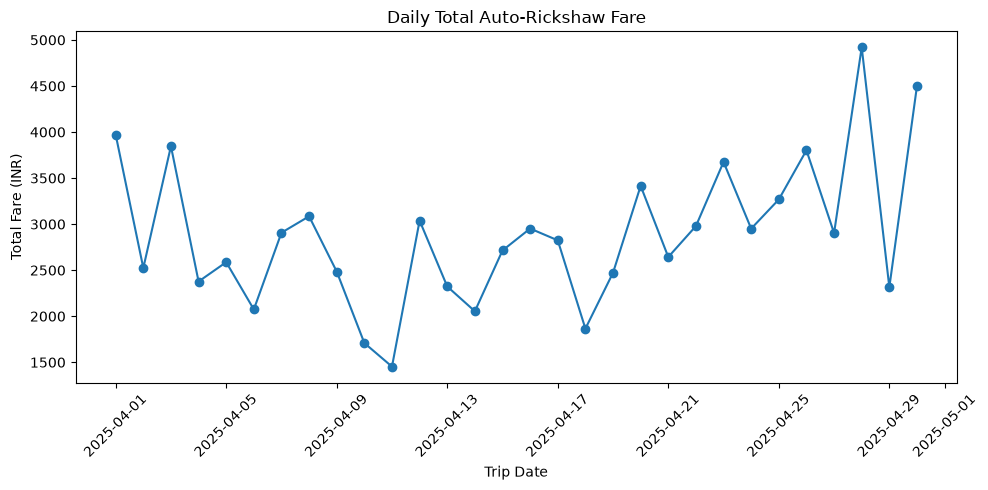

In [5]:
plt.figure(figsize=(10, 5))

plt.plot(daily_fare.index, daily_fare.values, marker="o")

plt.title("Daily Total Auto-Rickshaw Fare")
plt.xlabel("Trip Date")
plt.ylabel("Total Fare (INR)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig("daily_fare_line.png")
plt.show()

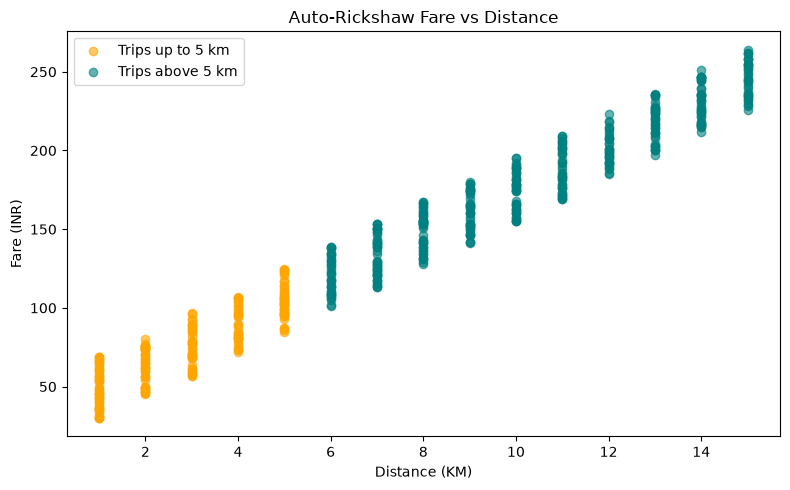

In [6]:
# Separate short and long trips
short_trips = trips[trips["distance_km"] <= 5]

long_trips = trips[trips["distance_km"] > 5]

# Create figure
plt.figure(figsize=(8, 5))

# Short trips in orange
plt.scatter(
    short_trips["distance_km"],
    short_trips["fare_inr"],
    color="orange",
    alpha=0.6,
    label="Trips up to 5 km"
)

# Long trips in teal
plt.scatter(
    long_trips["distance_km"],
    long_trips["fare_inr"],
    color="teal",
    alpha=0.6,
    label="Trips above 5 km"
)

plt.title("Auto-Rickshaw Fare vs Distance")
plt.xlabel("Distance (KM)")
plt.ylabel("Fare (INR)")
plt.legend()

plt.tight_layout()
plt.savefig("fare_vs_distance.png")
plt.show()

In [7]:
area_counts = trips["area"].value_counts().sort_values(ascending=False)

print("Trips per area:")
print(area_counts)

Trips per area:
area
Paldi          136
Navrangpura    121
Maninagar      116
Satellite      114
Vastrapur      113
Name: count, dtype: int64


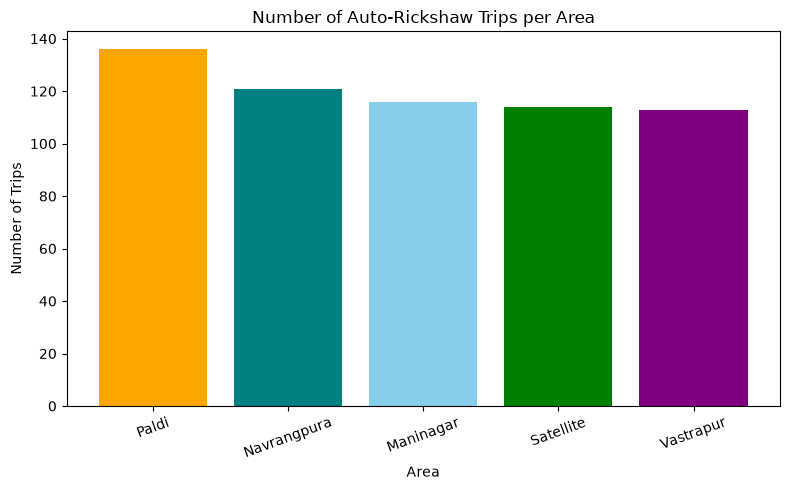

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))

# Different colour for each bar
colors = ["orange", "teal", "skyblue", "green", "purple"]

ax.bar(
    area_counts.index,
    area_counts.values,
    color=colors
)

ax.set_title("Number of Auto-Rickshaw Trips per Area")
ax.set_xlabel("Area")
ax.set_ylabel("Number of Trips")

plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig("trips_per_area.png")
plt.show()

In [9]:
mean_fare = trips["fare_inr"].mean()

print("Average Fare:", round(mean_fare, 2))

Average Fare: 144.38


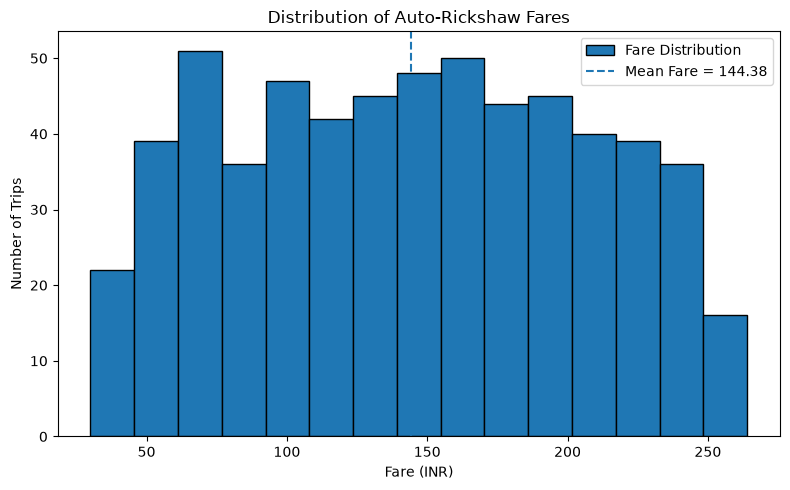

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))

# Draw histogram
ax.hist(
    trips["fare_inr"],
    bins=15,
    edgecolor="black",
    label="Fare Distribution"
)

# Draw mean line
ax.axvline(
    mean_fare,
    linestyle="--",
    label=f"Mean Fare = {mean_fare:.2f}"
)

ax.set_title("Distribution of Auto-Rickshaw Fares")
ax.set_xlabel("Fare (INR)")
ax.set_ylabel("Number of Trips")

ax.legend()

plt.tight_layout()
plt.savefig("fare_hist.png")
plt.show()

In [11]:
files = [
    "daily_fare_line.png",
    "fare_vs_distance.png",
    "trips_per_area.png",
    "fare_hist.png"
]

for file in files:
    print(file, ":", Path(file).exists())

# Check whether all images exist
assert all(Path(file).exists() for file in files)

print("\nAll four PNG files are saved successfully!")

daily_fare_line.png : True
fare_vs_distance.png : True
trips_per_area.png : True
fare_hist.png : True

All four PNG files are saved successfully!


In [12]:
print("First 5 rows:")
print(trips.head())

print("\nDataset Shape:")
print(trips.shape)

print("\nData Types:")
print(trips.dtypes)

print("\nTotal Fare:", trips["fare_inr"].sum())

print("\nMissing Values:")
print(trips.isna().sum())

First 5 rows:
   trip_id  trip_date         area  distance_km  fare_inr
0        1 2025-04-07  Navrangpura           10       189
1        2 2025-04-20        Paldi           13       214
2        3 2025-04-29        Paldi            8       143
3        4 2025-04-15        Paldi           14       234
4        5 2025-04-11    Satellite            2        45

Dataset Shape:
(600, 5)

Data Types:
trip_id                 int64
trip_date      datetime64[us]
area                      str
distance_km             int32
fare_inr                int32
dtype: object

Total Fare: 86630

Missing Values:
trip_id        0
trip_date      0
area           0
distance_km    0
fare_inr       0
dtype: int64
